In [6]:

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

os.makedirs("results", exist_ok=True)


TensorFlow version: 2.21.0
GPU available: []


In [7]:


import os
import pandas as pd

# Read the dataset already uploaded to Google Colab
filename = "/content/Dig-MNIST.csv (1).zip"

if not os.path.exists(filename):
    raise FileNotFoundError(
        f"Could not find {filename}. "
        "Check the filename in the Colab Files panel."
    )

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns[:10].tolist())
display(df.head())


Dataset loaded successfully!
Dataset shape: (10240, 785)
Column names: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8']


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:

# Extract labels
if "label" not in df.columns:
    raise ValueError(
        "The CSV must contain a 'label' column. "
        "Upload the labelled train.csv file, not test.csv."
    )

y = df["label"].to_numpy().astype("int64")

# Extract the 784 pixel columns, ignoring any optional ID column
pixel_cols = [
    col for col in df.columns
    if col != "label" and (
        str(col).lower().startswith("pixel")
        or str(col).isdigit()
    )
]

if len(pixel_cols) != 784:
    # Fallback: select all numeric columns except label and common IDs
    excluded = {"label", "id", "imageid"}
    pixel_cols = [
        col for col in df.columns
        if str(col).lower() not in excluded
        and pd.api.types.is_numeric_dtype(df[col])
    ]

    # If an ID column is present, remove it
    if len(pixel_cols) == 785:
        pixel_cols = [
            col for col in pixel_cols
            if str(col).lower() not in {"id", "imageid"}
        ]

if len(pixel_cols) != 784:
    raise ValueError(
        f"Expected 784 pixel columns but found {len(pixel_cols)}. "
        "Check the CSV format."
    )

X_images = df[pixel_cols].to_numpy(dtype="float32")
X_images = X_images.reshape(-1, 28, 28) / 255.0

# Required sequential representation:
# samples x time steps x features = N x 28 x 28
X = X_images.copy()

num_classes = len(np.unique(y))

print("Sequential input shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))
print("Number of classes:", num_classes)

assert X.shape[1:] == (28, 28)
assert num_classes == 10, "Expected all 10 digit classes."


Sequential input shape: (10240, 28, 28)
Labels shape: (10240,)
Classes: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10


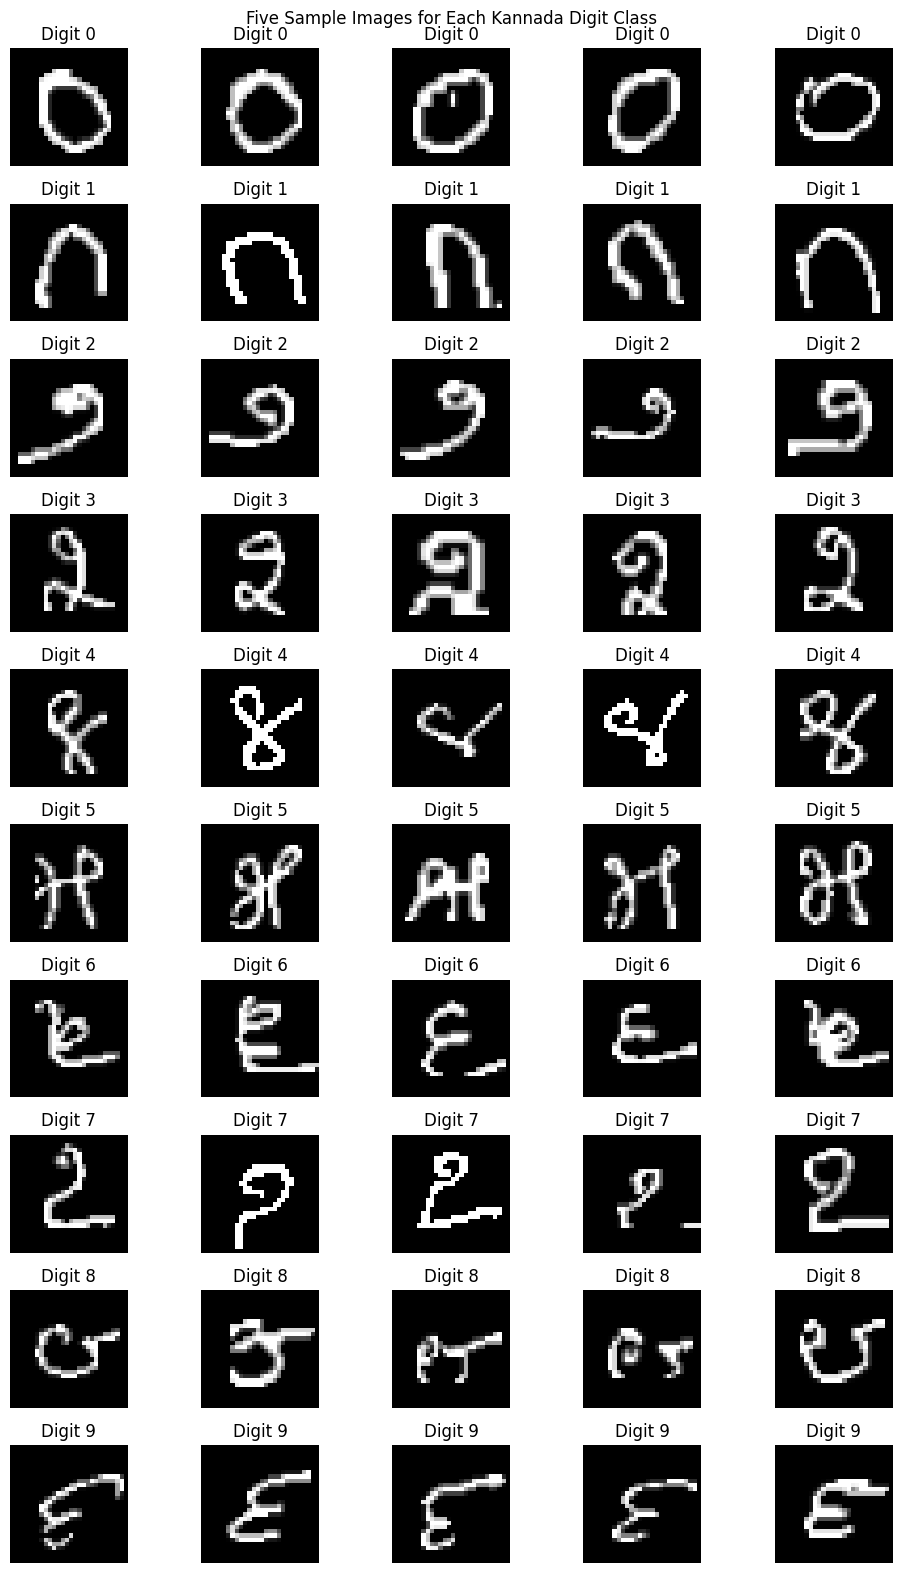

In [9]:

fig, axes = plt.subplots(10, 5, figsize=(10, 16))

for digit in range(10):
    indices = np.where(y == digit)[0][:5]

    for j in range(5):
        ax = axes[digit, j]

        if j < len(indices):
            ax.imshow(X_images[indices[j]], cmap="gray")
            ax.set_title(f"Digit {digit}")
        ax.axis("off")

plt.suptitle("Five Sample Images for Each Kannada Digit Class")
plt.tight_layout()
plt.savefig("results/digit_samples.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nInput shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training samples: 7168
Validation samples: 1536
Test samples: 1536

Input shapes:
Training: (7168, 28, 28)
Validation: (1536, 28, 28)
Test: (1536, 28, 28)


In [11]:

CONFIGS = [
    {
        "name": "RNN_64_lr001",
        "model": "RNN",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "RNN_128_lr001",
        "model": "RNN",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.001
    },
    {
        "name": "LSTM_64_lr001",
        "model": "LSTM",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "LSTM_128_lr0005",
        "model": "LSTM",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.0005
    },
    {
        "name": "GRU_64_lr001",
        "model": "GRU",
        "units": 64,
        "dropout": 0.0,
        "learning_rate": 0.001
    },
    {
        "name": "GRU_128_lr0005",
        "model": "GRU",
        "units": 128,
        "dropout": 0.2,
        "learning_rate": 0.0005
    }
]

EPOCHS = 20
BATCH_SIZE = 128

def build_model(config):
    model = Sequential()
    model.add(tf.keras.Input(shape=(28, 28)))

    layer_type = {
        "RNN": SimpleRNN,
        "LSTM": LSTM,
        "GRU": GRU
    }[config["model"]]

    model.add(
        layer_type(
            config["units"],
            dropout=config["dropout"]
        )
    )
    model.add(Dense(64, activation="relu"))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=config["learning_rate"]
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

print("Total configurations:", len(CONFIGS))


Total configurations: 6


In [12]:

histories = {}
models = {}
results = []

for config in CONFIGS:
    print("\n" + "=" * 65)
    print("Training:", config["name"])
    print("=" * 65)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(config)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    # Evaluate restored best-validation-loss weights
    train_loss, train_acc = model.evaluate(
        X_train, y_train, verbose=0
    )
    val_loss, val_acc = model.evaluate(
        X_val, y_val, verbose=0
    )
    test_loss, test_acc = model.evaluate(
        X_test, y_test, verbose=0
    )

    histories[config["name"]] = history.history
    models[config["name"]] = model

    results.append({
        "Configuration": config["name"],
        "Architecture": config["model"],
        "Units": config["units"],
        "Dropout": config["dropout"],
        "Learning Rate": config["learning_rate"],
        "Epochs Trained": len(history.history["loss"]),
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Test Accuracy": test_acc,
        "Training Loss": train_loss,
        "Test Loss": test_loss
    })

    print(f"Training accuracy:   {train_acc:.4f}")
    print(f"Validation accuracy:  {val_acc:.4f}")
    print(f"Test accuracy:       {test_acc:.4f}")

results_df = pd.DataFrame(results)
results_df.to_csv("results/hyperparameter_results.csv", index=False)

print("\nAll experiments completed.")



Training: RNN_64_lr001
Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4314 - loss: 1.7888 - val_accuracy: 0.6042 - val_loss: 1.2265
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6844 - loss: 0.9909 - val_accuracy: 0.7142 - val_loss: 0.8705
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7561 - loss: 0.7687 - val_accuracy: 0.7526 - val_loss: 0.7581
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7893 - loss: 0.6742 - val_accuracy: 0.7891 - val_loss: 0.6807
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8115 - loss: 0.6076 - val_accuracy: 0.8008 - val_loss: 0.6530
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8290 - loss: 0.5621 - val_accuracy: 0.8079 - val_loss: 0.6362
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8436 - loss: 0.5188 - val_accuracy: 0.8112 - val_loss: 0.6176
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8514 - loss: 0.4877 - val_acc

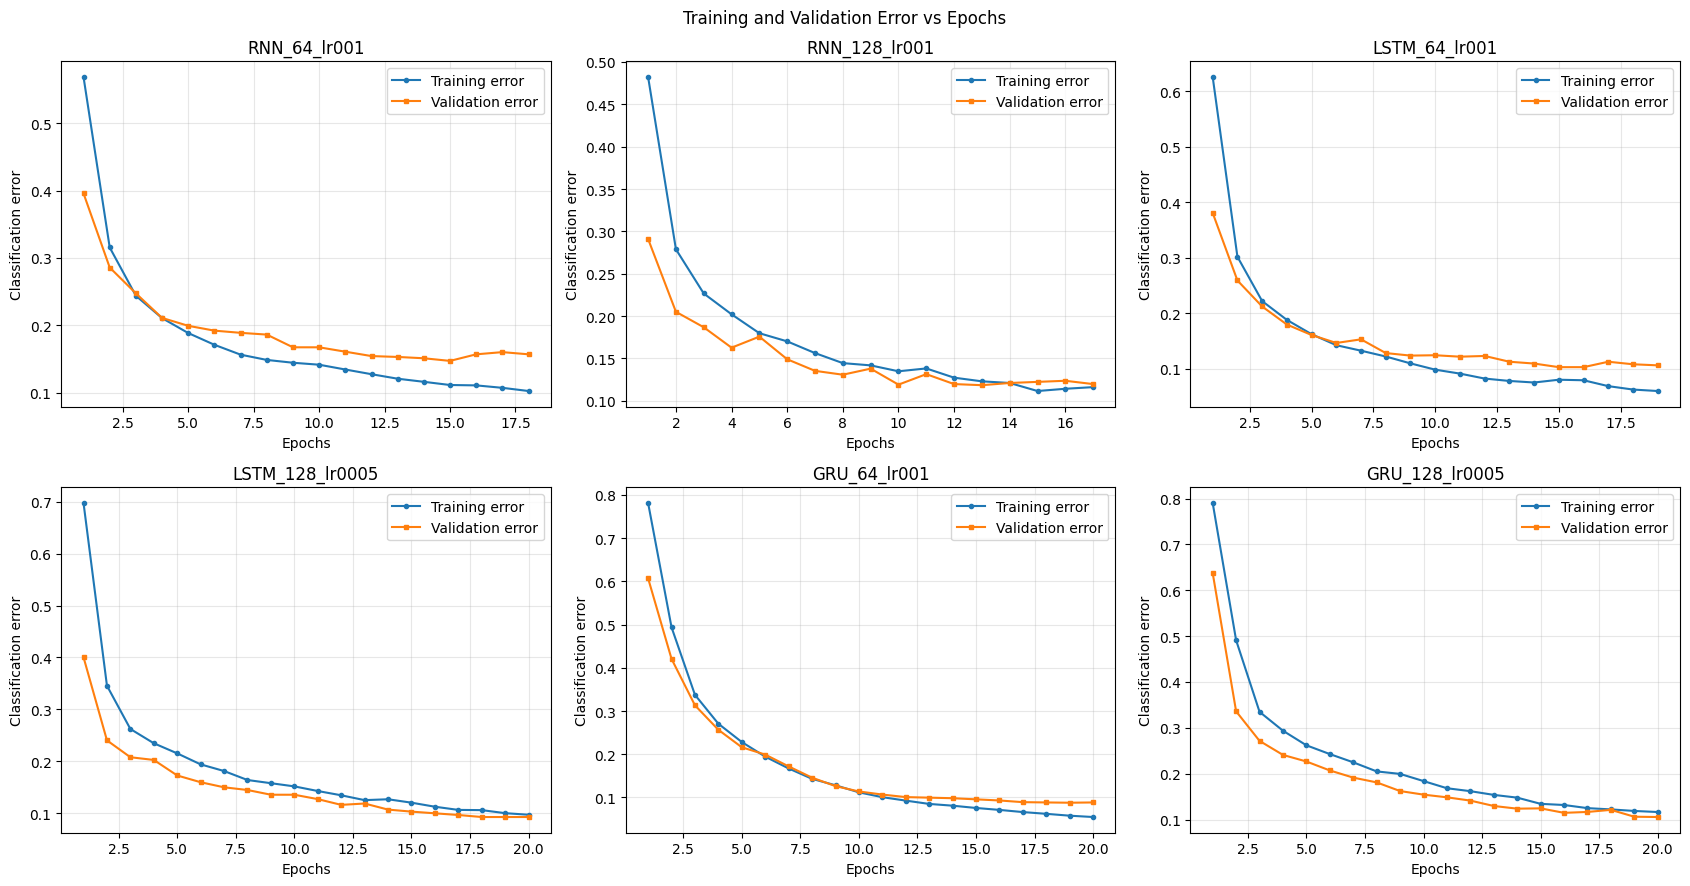

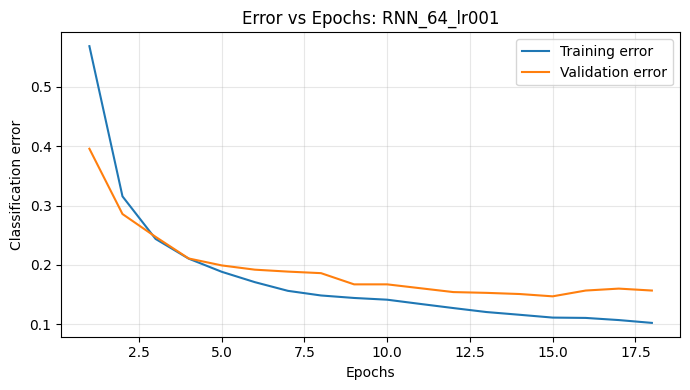

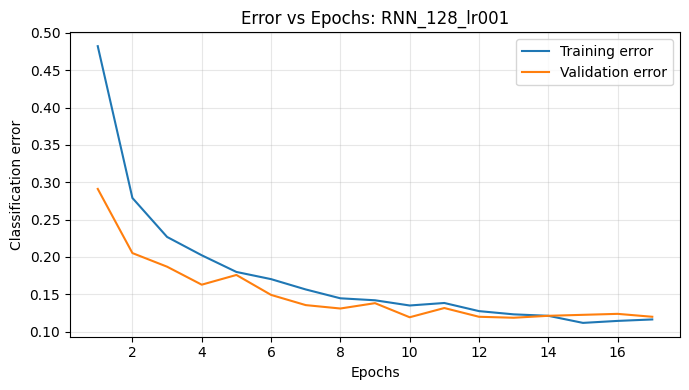

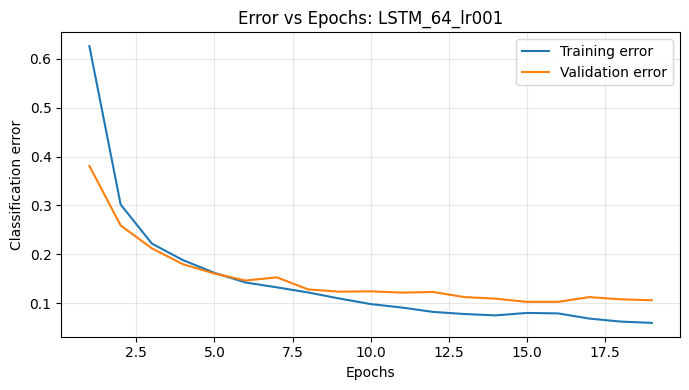

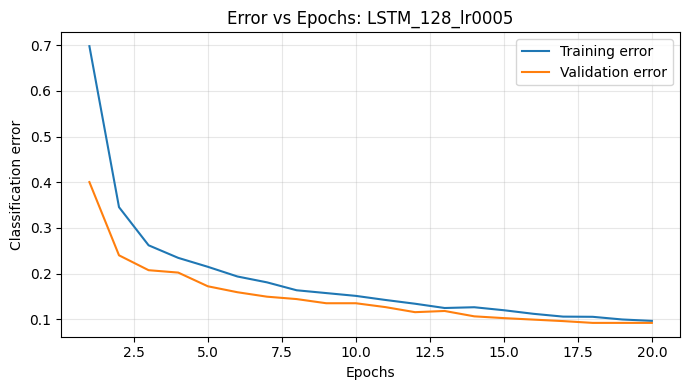

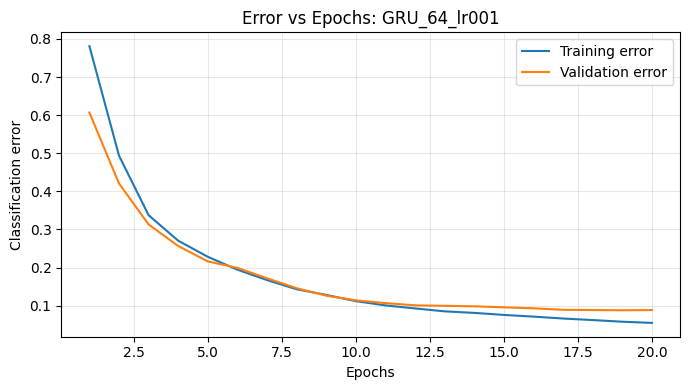

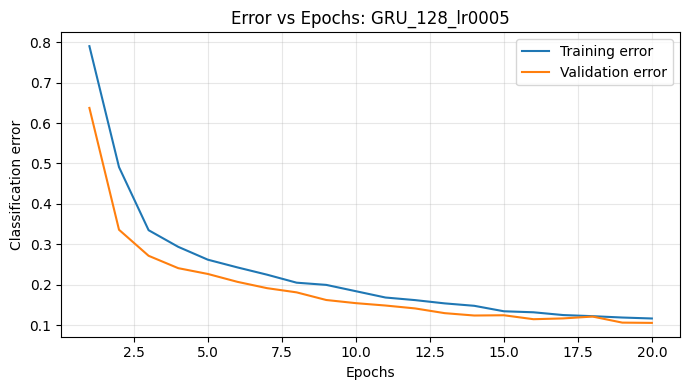

In [13]:

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
axes = axes.flatten()

for ax, config in zip(axes, CONFIGS):
    h = histories[config["name"]]

    train_error = 1 - np.array(h["accuracy"])
    val_error = 1 - np.array(h["val_accuracy"])

    epochs = np.arange(1, len(train_error) + 1)

    ax.plot(epochs, train_error, marker="o",
            markersize=3, label="Training error")
    ax.plot(epochs, val_error, marker="s",
            markersize=3, label="Validation error")

    ax.set_title(config["name"])
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Classification error")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Training and Validation Error vs Epochs")
plt.tight_layout()
plt.savefig("results/all_training_error_plots.png",
            dpi=200, bbox_inches="tight")
plt.show()

# Save an individual error plot for every configuration
for config in CONFIGS:
    h = histories[config["name"]]
    epochs = np.arange(1, len(h["accuracy"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs, 1 - np.array(h["accuracy"]),
             label="Training error")
    plt.plot(epochs, 1 - np.array(h["val_accuracy"]),
             label="Validation error")

    plt.title(f"Error vs Epochs: {config['name']}")
    plt.xlabel("Epochs")
    plt.ylabel("Classification error")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"results/error_{config['name']}.png",
        dpi=200, bbox_inches="tight"
    )
    plt.show()
    plt.close()


In [14]:

display_df = results_df[
    [
        "Configuration",
        "Architecture",
        "Units",
        "Dropout",
        "Learning Rate",
        "Epochs Trained",
        "Training Accuracy",
        "Validation Accuracy",
        "Test Accuracy"
    ]
].copy()

for col in [
    "Training Accuracy",
    "Validation Accuracy",
    "Test Accuracy"
]:
    display_df[col] = (100 * display_df[col]).round(2)

print("Accuracy comparison (percent):")
display(display_df)

display_df.to_csv(
    "results/accuracy_summary.csv",
    index=False
)


Accuracy comparison (percent):


,Configuration,Architecture,Units,Dropout,Learning Rate,Epochs Trained,Training Accuracy,Validation Accuracy,Test Accuracy
0,RNN_64_lr001,RNN,64,0.0,0.0010,18,88.85,84.90,85.48
1,RNN_128_lr001,RNN,128,0.2,0.0010,17,90.85,88.15,89.00
2,LSTM_64_lr001,LSTM,64,0.0,0.0010,19,93.44,89.71,90.30
3,LSTM_128_lr0005,LSTM,128,0.2,0.0005,20,93.09,90.76,89.91
4,GRU_64_lr001,GRU,64,0.0,0.0010,20,94.36,91.15,89.58
5,GRU_128_lr0005,GRU,128,0.2,0.0005,20,91.00,89.45,88.61


In [15]:

best_row = results_df.loc[
    results_df["Validation Accuracy"].idxmax()
]

best_name = best_row["Configuration"]
best_model = models[best_name]

print("Best configuration:", best_name)
print("Architecture:", best_row["Architecture"])
print("Hidden units:", best_row["Units"])
print("Dropout:", best_row["Dropout"])
print("Learning rate:", best_row["Learning Rate"])
print(f"Training accuracy: {100*best_row['Training Accuracy']:.2f}%")
print(f"Validation accuracy: {100*best_row['Validation Accuracy']:.2f}%")
print(f"Test accuracy: {100*best_row['Test Accuracy']:.2f}%")


Best configuration: GRU_64_lr001
Architecture: GRU
Hidden units: 64
Dropout: 0.0
Learning rate: 0.001
Training accuracy: 94.36%
Validation accuracy: 91.15%
Test accuracy: 89.58%


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
Best model: GRU_64_lr001
Final test accuracy: 89.58%

Classification report:
              precision    recall  f1-score   support

           0     0.8616    0.8954    0.8782       153
           1     0.8917    0.9150    0.9032       153
           2     0.9178    0.8701    0.8933       154
           3     0.9272    0.9091    0.9180       154
           4     0.8924    0.9156    0.9038       154
           5     0.9080    0.9610    0.9338       154
           6     0.8889    0.7792    0.8304       154
           7     0.8537    0.9150    0.8833       153
           8     0.8598    0.9156    0.8868       154
           9     0.9712    0.8824    0.9247       153

    accuracy                         0.8958      1536
   macro avg     0.8972    0.8958    0.8956      1536
weighted avg     0.8972    0.8958    0.8956      1536



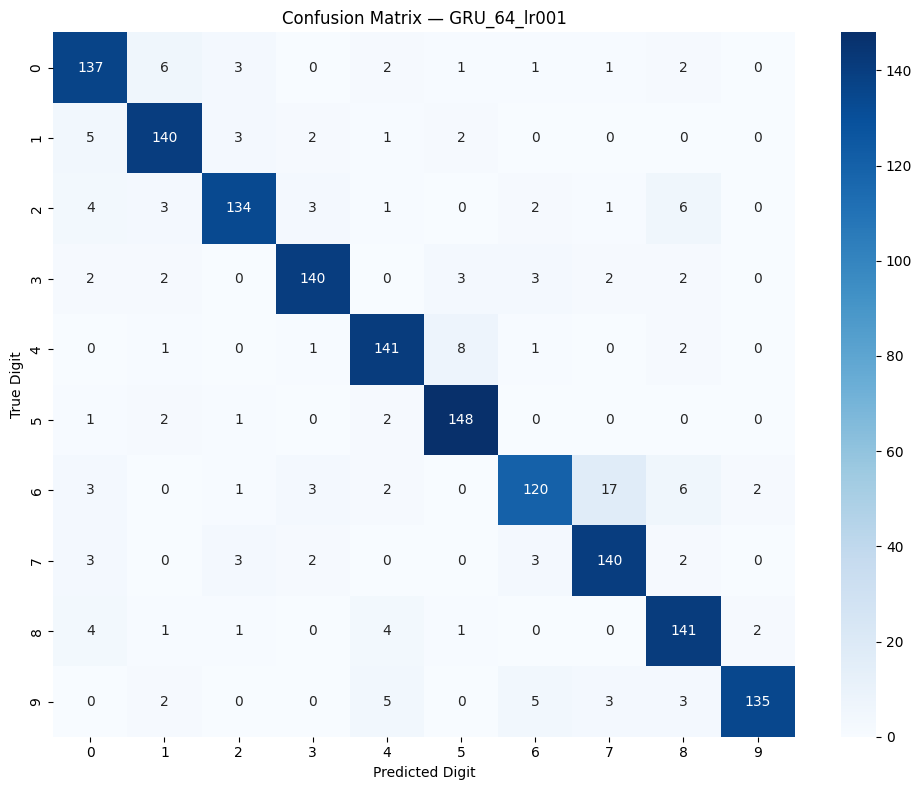

In [16]:

y_prob = best_model.predict(
    X_test, batch_size=BATCH_SIZE, verbose=1
)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=np.arange(10))

print(f"Best model: {best_name}")
print(f"Final test accuracy: {100*test_accuracy:.2f}%")
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(10),
        digits=4,
        zero_division=0
    )
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted Digit")
plt.ylabel("True Digit")
plt.tight_layout()
plt.savefig("results/best_confusion_matrix.png",
            dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame(
    cm,
    index=[f"True {i}" for i in range(10)],
    columns=[f"Predicted {i}" for i in range(10)]
).to_csv("results/confusion_matrix.csv")


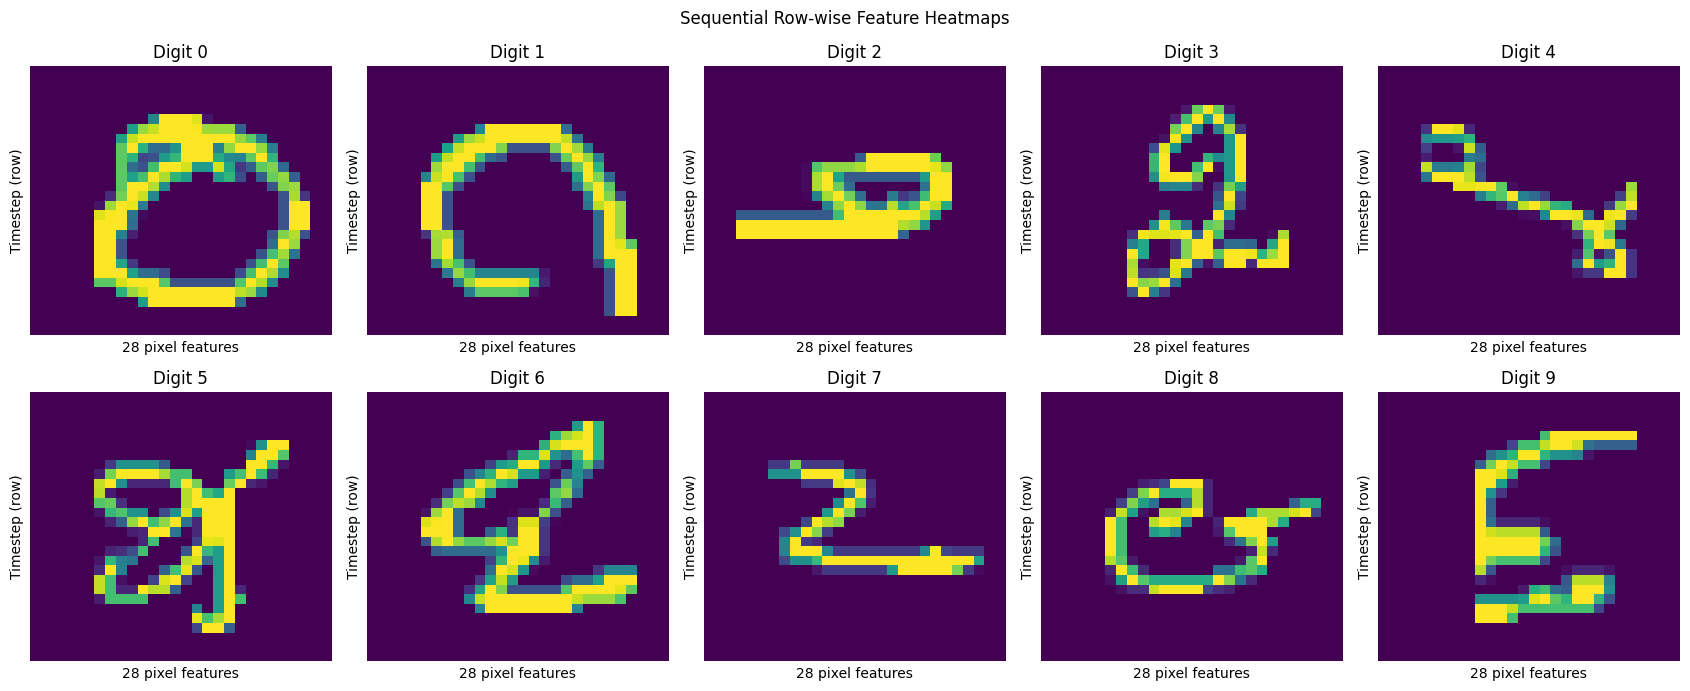

In [17]:

# Choose one test image from each digit class
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
axes = axes.flatten()

for digit in range(10):
    idx = np.where(y_test == digit)[0][0]

    # Each row is one timestep; each column is one pixel feature
    sequence = X_test[idx]

    sns.heatmap(
        sequence,
        ax=axes[digit],
        cmap="viridis",
        cbar=False,
        xticklabels=False,
        yticklabels=False
    )

    axes[digit].set_title(f"Digit {digit}")
    axes[digit].set_xlabel("28 pixel features")
    axes[digit].set_ylabel("Timestep (row)")

plt.suptitle("Sequential Row-wise Feature Heatmaps")
plt.tight_layout()
plt.savefig("results/sequential_feature_heatmaps.png",
            dpi=200, bbox_inches="tight")
plt.show()


  Architecture  Best_Validation_Accuracy  Best_Test_Accuracy
0          GRU                  0.911458            0.895833
1         LSTM                  0.907552            0.902995
2          RNN                  0.881510            0.889974


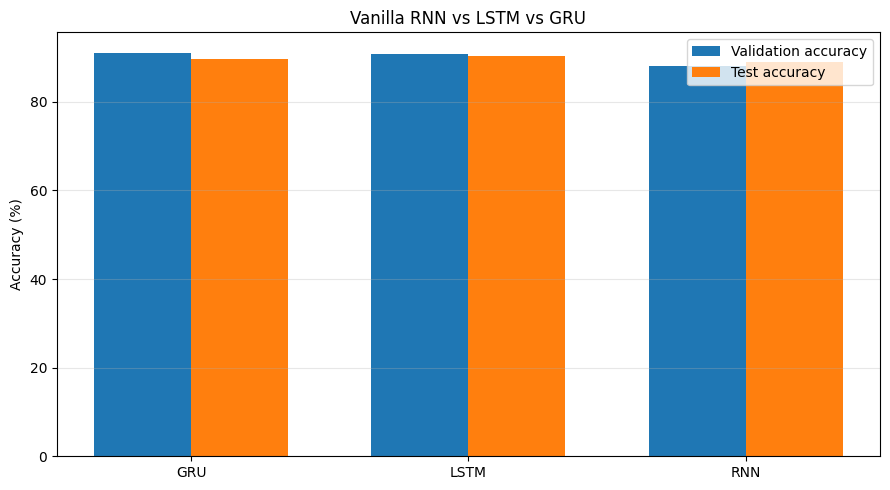

In [18]:

architecture_summary = (
    results_df.groupby("Architecture", as_index=False)
    .agg(
        Best_Validation_Accuracy=("Validation Accuracy", "max"),
        Best_Test_Accuracy=("Test Accuracy", "max")
    )
)

print(architecture_summary)

x = np.arange(len(architecture_summary))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(
    x - width/2,
    architecture_summary["Best_Validation_Accuracy"] * 100,
    width,
    label="Validation accuracy"
)
plt.bar(
    x + width/2,
    architecture_summary["Best_Test_Accuracy"] * 100,
    width,
    label="Test accuracy"
)

plt.xticks(x, architecture_summary["Architecture"])
plt.ylabel("Accuracy (%)")
plt.title("Vanilla RNN vs LSTM vs GRU")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("results/architecture_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()


In [21]:

import shutil

# Save the best model
best_model.save("results/best_model.keras")

# Save the complete experiment summary
results_df.to_csv("results/all_experiment_results.csv", index=False)

# Package figures, tables, confusion matrix, and best model
shutil.make_archive("Task1_Report_Results", "zip", "results")

files.download("Task1_Report_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>